## 13.Agents

<pre>
An AI Agent is an LLM-powered system that understands a user's goal, decides which actions to take, uses tools to perform those actions, observes the results, and repeats the process until the task is completed or a stopping condition is reached.
</pre>

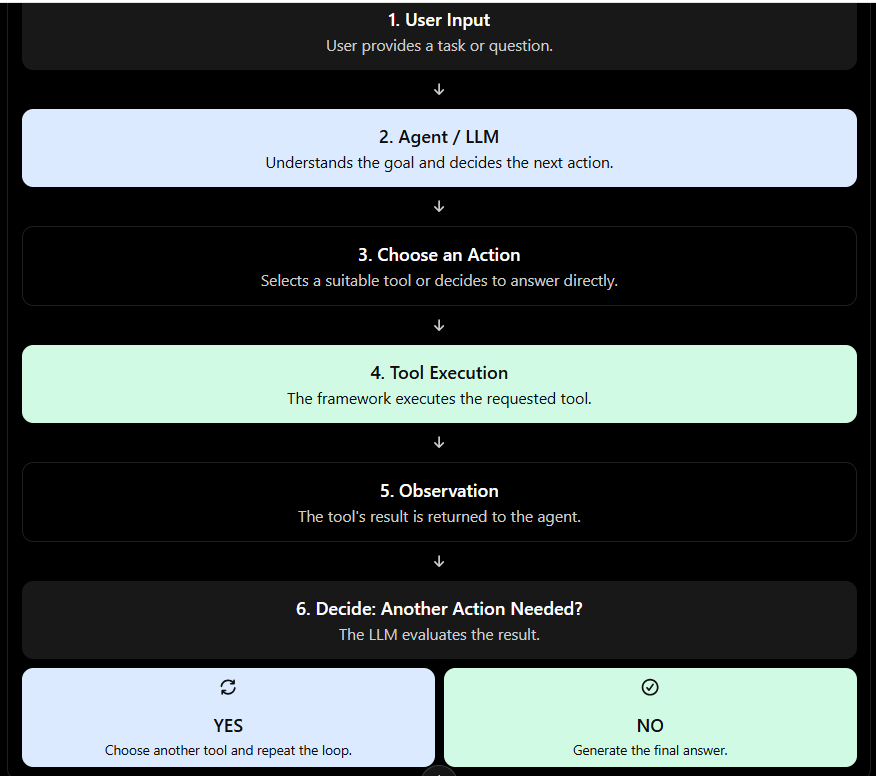

<pre>
Example

User asks: "Find the latest AI news and summarize it."

User input: Requests the latest AI news.

Agent: Decides that web search is required.

Action: Requests the Tavily search tool.

Tool execution: Tavily searches the web and returns results.

Observation: The agent receives the search results.

Decision: The LLM determines that it has enough information.

Final answer: The agent summarizes the relevant news for the user.

Remember: The LLM decides which tool to request, the framework executes it, and the result is fed back to the LLM. This repeated process is called the agent loop.

</pre>

In [1]:
from langchain_groq import ChatGroq

model=ChatGroq(model_name="openai/gpt-oss-20b")

<pre>
We've already learned Python functions as tools, @tool, bind_tools(), and Tavily web search. Now we're going to connect these concepts and actually build an agent.

The best part? Remember how you previously had to manually execute a tool after the LLM requested it? With LangChain's agent framework, we can automate that loop.
</pre>

## 13.1 - Create your first agent

In [4]:
from langchain_core.tools import tool

@tool
def multiply(a:int,b:int) -> int:
    """ Multiply two numbers and return the result."""
    return a*b

In [3]:
# Create your first agent
from langchain.agents import create_agent

agent=create_agent(
    model=model,
    tools=[multiply],
    system_prompt=(
        "You are a helpful assistant."
        "Use the multiply tool when a multiplication calculation is needed."
    )
)

In [4]:
# Run the agent

result=agent.invoke({
    "messages":[
        {
            "role":"user",
            "content":"What is 25 multiplied by 16?"
        }
    ]
})
print(result["messages"][-1].content)

25 multiplied by 16 equals **400**.


In [7]:
# Inspect the agent's complete workflow

for message in result["messages"]:
    print("Type:", type(message).__name__)
    print("Content:", message.content)

    if hasattr(message, "tool_calls") and message.tool_calls:
        print("Tool calls:", message.tool_calls)

    print("-" * 50)

Type: HumanMessage
Content: What is 25 multiplied by 16?
--------------------------------------------------
Type: AIMessage
Content: 
Tool calls: [{'name': 'multiply', 'args': {'a': 25, 'b': 16}, 'id': 'fc_376c62c0-ae2c-42fb-b422-02daf0332c2c', 'type': 'tool_call'}]
--------------------------------------------------
Type: ToolMessage
Content: 400
--------------------------------------------------
Type: AIMessage
Content: 25 multiplied by 16 equals **400**.
--------------------------------------------------


The first AIMessage requests the tool.

The second AIMessage provides the final answer after receiving the tool result.<br>
Between those messages, your agent framework executes the Python function. That's the automated agent loop in action!

## 13.2 - Multiple tools

In [5]:
# Create the Tavily search tool
from langchain_tavily import TavilySearch

web_search=TavilySearch(max_results=3)
print("Tool name:",web_search.name)
print("Tool description:",web_search.description)

Tool name: tavily_search
Tool description: A search engine optimized for comprehensive, accurate, and trusted results. Useful for when you need to answer questions about current events. It not only retrieves URLs and snippets, but offers advanced search depths, domain management, time range filters, and image search, this tool delivers real-time, accurate, and citation-backed results.Input should be a search query.


In [13]:
from langchain.agents import create_agent

agent=create_agent(
    model=model,
    tools=[multiply,web_search],
    system_prompt="""
    You are a helpful research and calculation assistant.

    Rules:
    1. For current factual information, use web_search.
    2. Use at most two web searches for one user question.
    3. After finding a sufficiently reliable answer, stop searching.
    4. If the user requests a calculation, use the multiply tool.
    5. Use the information returned by the search when calculating.
    6. Explain the source, the number used, and the calculation.
    7. Never invent facts or claim a tool was used when it was not.
    """
)


In [11]:
result=agent.invoke({
    "messages":[
        {"role":"user","content":"What is the latest news about cricket?"}
    ]
})
print(result["messages"][-1].content)

Here are the most recent cricket headlines that surfaced in the last few days:

| Date (GMT) | Headline | Key Take‑away |
|------------|----------|---------------|
| **Sun, 11 Oct 2026** | *What happened in the last 5 matches at Holkar Stadium in Indore?* – Yahoo Sports | India’s T20I series against the West Indies is in full swing. The 3rd T20I is scheduled for 7 PM IST on 11 Oct 2026. The article also includes toss trends, pitch reports and recent match outcomes. |
| **Sat, 10 Oct 2026** | *How to watch Ranji Trophy 2026/27?* – Yahoo Sports | The Ranji Trophy, India’s premier domestic competition, begins on 11 Oct 2026 and will run until 3 Mar 2027. The article lists TV channels (Star Sports) and streaming options (JioHotstar). |
| **Fri, 9 Oct 2026** | *Hong Kong Sixes 2026 schedule* – Cricket News | The Hong Kong Sixes tournament starts on 30 Oct 2026. The schedule lists all group‑stage matches, including India vs. Pakistan, Bangladesh vs. Sri Lanka, and England vs. Australia. |

*

In [12]:
for message in result["messages"]:
    print("Type:", type(message).__name__)
    print("Content:", message.content)

    if getattr(message, "tool_calls", None):
        print("Tool calls:", message.tool_calls)

    print("-" * 50)

Type: HumanMessage
Content: What is the latest news about cricket?
--------------------------------------------------
Type: AIMessage
Content: 
Tool calls: [{'name': 'tavily_search', 'args': {'query': 'latest cricket news 2026', 'search_depth': 'basic', 'topic': 'news'}, 'id': 'fc_3998daf9-63fd-4492-8d2a-9a9aa544f30f', 'type': 'tool_call'}]
--------------------------------------------------
Type: ToolMessage
Content: {"query": "latest cricket news 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://sports.yahoo.com/articles/happened-last-5-matches-holkar-013002373.html", "title": "What happened in the last 5 matches at Holkar Stadium in Indore? Results, toss trends and pitch report - Yahoo Sports", "content": "MORE:Shreyas Iyer blames dew after WI blow India away in a 250 chase\n\n## Upcoming schedule at Holkar Stadium in India vs West Indies T20I series\n\n|  |  |  |  |  |\n ---  --- \n| Match No. |  |  |  | Local time (IST) |\n| 3rd T20I | O

## 13.3 - Multi-step tool calling

Understand the problem

You already have two tools:

multiply(a, b) — multiplies two numbers.

web_search — searches the internet using Tavily.

Imagine the user asks:

Search for the population of Tokyo and multiply it by 2.

The agent may need to perform two tool calls before answering.

In [14]:
question="""
Find a recent population estimate for Tokyo and multiply it by 2.

"""
result=agent.invoke({
    "messages":[
        {"role":"user","content":question}
    ]
})
print(result["messages"][-1].content)

**Tokyo population estimate (most recent)**  
- **Source:** Tokyo Metropolitan Government, “Population for Tokyo” (estimates as of October 1 2025).  
- **Number:** **14,273,066** residents【3†L5-L12】.

**Multiplication**

\[
14,273,066 \times 2 = 28,546,132
\]

**Result:** The doubled estimate is **28,546,132**.


In [15]:
for message in result["messages"]:
    print("\nType:", type(message).__name__)

    if message.content:
        print("Content:", message.content)

    if getattr(message, "tool_calls", None):
        for call in message.tool_calls:
            print("Tool selected:", call["name"])
            print("Arguments:", call["args"])

    print("-" * 50)


Type: HumanMessage
Content: 
Find a recent population estimate for Tokyo and multiply it by 2.


--------------------------------------------------

Type: AIMessage
Tool selected: tavily_search
Arguments: {'query': 'recent population estimate for Tokyo 2024', 'search_depth': 'basic', 'topic': 'general'}
--------------------------------------------------

Type: ToolMessage
Content: {"query": "recent population estimate for Tokyo 2024", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.stat.go.jp/english/data/jinsui/2024np/index.html", "title": "Statistics Bureau Home Page/Population Estimates/Current Population Estimates as of October 1, 2024", "content": "The population increased in Tokyo-to and Saitama-ken. Tokyo-to had the highest rate of increase in population.\n The population decreased in 45 prefectures. Akita-ken had the highest rate of decrease in population.\n\n[Population by Age Group] [...] [Population]\n\n The top five prefectures i

In [16]:
for i, message in enumerate(result["messages"]):
    print(f"\n--- Message {i + 1} ---")
    print("Type:", type(message).__name__)

    # Show any tools requested by the model
    tool_calls = getattr(message, "tool_calls", [])
    if tool_calls:
        for call in tool_calls:
            print("Tool:", call["name"])
            print("Arguments:", call["args"])

    # Show a short preview of tool results
    elif type(message).__name__ == "ToolMessage":
        print("Tool result preview:", str(message.content)[:300])

    # Show the final response
    elif type(message).__name__ == "AIMessage":
        print("Response:", str(message.content)[:500])


--- Message 1 ---
Type: HumanMessage

--- Message 2 ---
Type: AIMessage
Tool: tavily_search
Arguments: {'query': 'recent population estimate for Tokyo 2024', 'search_depth': 'basic', 'topic': 'general'}

--- Message 3 ---
Type: ToolMessage
Tool result preview: {"query": "recent population estimate for Tokyo 2024", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.stat.go.jp/english/data/jinsui/2024np/index.html", "title": "Statistics Bureau Home Page/Population Estimates/Current Population Estimates as of October 

--- Message 4 ---
Type: AIMessage
Tool: tavily_search
Arguments: {'query': 'Tokyo population estimate 2024 11.5 percent of total population 11.5 million', 'search_depth': 'basic'}

--- Message 5 ---
Type: ToolMessage
Tool result preview: {"query": "Tokyo population estimate 2024 11.5 percent of total population 11.5 million", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.stat.go.jp/engli

In [17]:
for i, message in enumerate(result["messages"]):
    calls = getattr(message, "tool_calls", [])

    if calls:
        for call in calls:
            print(f"Message {i + 1}: {call['name']}")

    elif type(message).__name__ == "ToolMessage":
        print(f"Message {i + 1}: Tool result from {message.name}")

Message 2: tavily_search
Message 3: Tool result from tavily_search
Message 4: tavily_search
Message 5: Tool result from tavily_search
Message 6: tavily_search
Message 7: Tool result from tavily_search
Message 8: multiply
Message 9: Tool result from multiply


<pre>
What you learned in Module 17.3

An agent can call multiple tools during one request.

It can call the same tool repeatedly.

Tool results return to the model as observations.

The model decides what action to take next.

System prompts can guide tool usage, but prompts alone don't enforce strict execution limits

</pre>

## 17.4 - Controlling Agent Behavior!

<pre>
Problem 1: Too many tool calls

Your Tokyo example called Tavily six times before using multiply.

Solution: Set an execution limit and give the agent clear stopping instructions.

</pre>

In [18]:
from langchain.agents import create_agent

agent=create_agent(
    model=model,
    tools=[multiply,web_search],
    system_prompt="""
     You are a helpful research assistant.

    1. Use web search for current information.
    2. Search at most twice for one question.
    3. Stop searching when you have enough information.
    4. Use multiply for multiplication calculations.
    5. Give a clear final answer.
    """
)

This instruction guides the model to search less. Remember, though, a prompt is not a strict enforcement mechanism; we'll use runtime controls for that.

In [19]:
try:
    result = agent.invoke(
        {
            "messages": [
                {
                    "role": "user",
                    "content": (
                        "Search for Tokyo's population "
                        "and multiply it by 2."
                    )
                }
            ]
        },
        config={"recursion_limit": 10}
    )

    print(result["messages"][-1].content)

except Exception as e:
    print("Agent stopped or failed:", type(e).__name__)
    print("Details:", e)

**Tokyo’s population (2024):** 14,192,184  
**Twice that number:** 28,384,368  

*(Source: “Demographics of Tokyo” – 2024 figure of 14,192,184 residents.)*


recursion_limit=10 limits graph execution steps, not ten tool calls.

try attempts to execute the agent.

except catches an exception, including a recursion-limit error, and displays its details.

If the limit is reached, the agent may stop before producing a final answer.

## ReAct

ReAct = Reason + Act

It's a framework for an LLM to solve tasks by alternating between reasoning about what to do and taking actions using tools, then observing the results.

Reason — decide what information or action is needed.

Act — call a tool.

Observe — receive the tool's result.

Repeat if necessary, then provide the final answer.

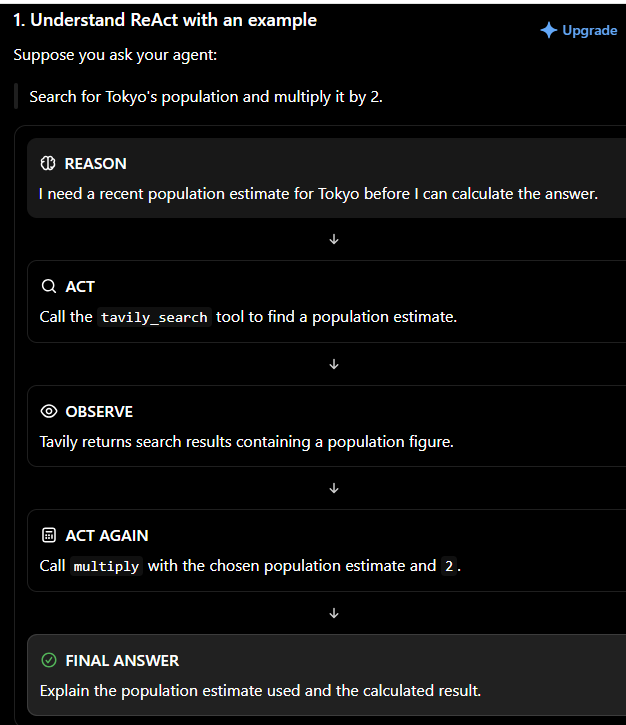

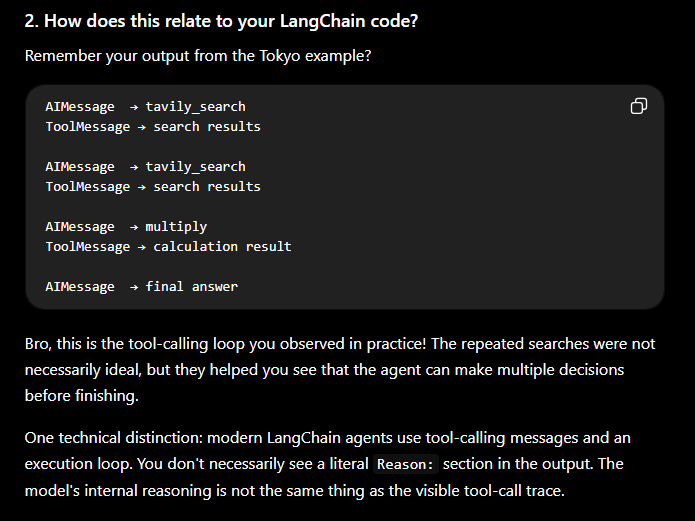

3.Do you need to implement ReAct manually?

No, bro! When you're using create_agent() with tools, LangChain manages the main execution loop. You provide the model, tools, and instructions.

You can inspect the tool calls and results to understand the process without writing the entire loop yourself.